# De la donnée à la décision — Statistiques pour les Experts Data

## TP 01 — Statistiques descriptives

**Auteur :** Bassem Ben Hamed — `bassem.benhamed@enetcom.usf.tn`

**Contenu :** Modules 0 à 3 de la formation (Partie 1 — Statistiques descriptives).

**Dataset fil rouge :** *Pharmaceutical Sales Data* (Kaggle / Milan Sulc) — ventes journalières de 8 catégories ATC sur 2014-2019.

Ce notebook accompagne le module 01 Statistiques descriptives. Pour chaque concept :
1. **Rappel théorique** (formule + intuition).
2. **Code commenté** en français.
3. **Interprétation business** systématique.

> Les formules sont rappelées dans le notebook même si elles figurent déjà dans les slides — la répétition est volontaire pour fixer les notations.

## Sommaire

- **Setup** — imports, génération du dataset
- **Module 0** — Introduction & Cadrage
  - Vocabulaire (population, échantillon, paramètre, estimation)
  - Types de variables
- **Module 1** — Décrire une variable
  - Tendance centrale (moyenne, médiane, mode)
  - Dispersion (variance, écart-type, IQR, CV)
  - Forme (skewness, kurtosis)
  - Quantiles & boxplot (règle de Tukey)
  - Lecture critique de `describe()`
- **Module 2** — Visualiser une distribution
  - Histogramme & KDE (Sturges, Freedman-Diaconis)
  - Lois usuelles (normale, log-normale, Poisson, binomiale)
  - Échelle log
- **Module 3** — Relations entre deux variables
  - Quanti-Quanti (covariance, Pearson, Spearman)
  - Quali-Quanti (décomposition de variance, $\eta^2$)
  - Quali-Quali ($\chi^2$, V de Cramér)
  - Matrice de corrélation, paradoxe de Simpson
- **Synthèse**

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

np.random.seed(42)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 12
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

### Chargement du dataset

Le dataset est dans `dataset/salesdaily.csv` (source : [Kaggle — Pharma Sales Data, Milan Zdravković](https://www.kaggle.com/datasets/milanzdravkovic/pharma-sales-data), licence CC BY-NC 4.0).

**Caractéristiques :**
- 8 catégories ATC : `M01AB`, `M01AE`, `N02BA`, `N02BE`, `N05B`, `N05C`, `R03`, `R06`.
- Période : janvier 2014 → 8 octobre 2019 (~2 100 jours, dernière année incomplète).
- Granularité journalière. Les valeurs sont des **volumes agrégés** (flottants), pas des comptes d'unités.
- Issu d'une **seule pharmacie** — point d'attention pour la généralisation.

In [2]:
from pathlib import Path

csv_path = Path('dataset') / 'salesdaily.csv'
df_raw = pd.read_csv(csv_path, parse_dates=['datum'], dayfirst=False)
df_raw = df_raw.rename(columns={'datum': 'date'}).set_index('date').sort_index()

# On isole les 8 colonnes de ventes (les autres sont des features de date redondantes)
categories = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']
df = df_raw[categories].copy()

print(f'Forme : {df.shape}')
print(f'Période : {df.index.min().date()} -> {df.index.max().date()}')
df.head()

Forme : (2106, 8)
Période : 2014-01-02 -> 2019-10-08


,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
date,,,,,,,,
2014-01-02,0.00,3.67,3.40,32.40,7.00,0.00,0.00,2.00
2014-01-03,8.00,4.00,4.40,50.60,16.00,0.00,20.00,4.00
2014-01-04,2.00,1.00,6.50,61.85,10.00,0.00,9.00,1.00
2014-01-05,4.00,3.00,7.00,41.10,8.00,0.00,3.00,0.00
2014-01-06,5.00,1.00,4.50,21.70,16.00,2.00,6.00,2.00


---
## Module 0 — Introduction & Cadrage

### Trois grandes familles d'outils

| Famille | Question type | Exemple sur notre dataset |
|---|---|---|
| **Descriptive** | « À quoi ressemblent mes données ? » | Quelle est la distribution des ventes de R06 ? |
| **Inférentielle** | « Y a-t-il une vraie différence ? » | Les ventes du week-end sont-elles significativement plus basses ? |
| **Séries temporelles** | « Que va-t-il se passer demain ? » | Combien de N02BE va-t-on vendre en janvier 2020 ? |

Ce notebook se concentre sur la **statistique descriptive**.

### Vocabulaire et notations

| Concept | Population (vrai) | Échantillon (estimé) |
|---|---|---|
| Moyenne | $\mu$ | $\bar{x}$ |
| Variance | $\sigma^2$ | $s^2$ |
| Écart-type | $\sigma$ | $s$ |
| Proportion | $p$ | $\hat{p}$ |

Notre DataFrame est un **échantillon** de 6 ans. La « vraie » distribution sous-jacente (la population) reste inconnue — on l'**estime**.

In [3]:
# Vue rapide — taille de l'échantillon
n = len(df)
print(f'Taille de l\'échantillon n = {n} jours')
print(f'Soit {n / 365.25:.1f} années de données')

Taille de l'échantillon n = 2106 jours
Soit 5.8 années de données


### Types de variables

| Famille | Sous-type | Variable du dataset |
|---|---|---|
| Quantitative | Continue | Ventes (`R06`, `N02BE`, ...) |
| Quantitative | Discrète | Nombre de transactions (non disponible ici) |
| Qualitative | Nominale | Catégorie ATC, jour de la semaine |
| Qualitative | Ordinale | Saison (hiver < printemps < ... — discutable) |

**Conséquence :** on ne calcule pas une moyenne sur la catégorie ATC, et on ne fait pas un $\chi^2$ sur les ventes brutes.

On enrichit le DataFrame avec des variables qualitatives utiles pour la suite :

In [4]:
# Enrichissement : variables temporelles dérivées
JOURS_FR = {0: 'lundi', 1: 'mardi', 2: 'mercredi', 3: 'jeudi',
            4: 'vendredi', 5: 'samedi', 6: 'dimanche'}

def saison(mois):
    return ('hiver' if mois in (12, 1, 2)
            else 'printemps' if mois in (3, 4, 5)
            else 'été' if mois in (6, 7, 8)
            else 'automne')

df_long = df.stack().rename('ventes').reset_index()
df_long.columns = ['date', 'categorie', 'ventes']
df_long['jour_semaine'] = df_long['date'].dt.dayofweek.map(JOURS_FR)
df_long['mois']         = df_long['date'].dt.month
df_long['annee']        = df_long['date'].dt.year
df_long['weekend']      = df_long['date'].dt.dayofweek >= 5
df_long['saison']       = df_long['mois'].map(saison)

df_long.head()

,date,categorie,ventes,jour_semaine,mois,annee,weekend,saison
0,2014-01-02,M01AB,0.00,jeudi,1,2014,False,hiver
1,2014-01-02,M01AE,3.67,jeudi,1,2014,False,hiver
2,2014-01-02,N02BA,3.40,jeudi,1,2014,False,hiver
3,2014-01-02,N02BE,32.40,jeudi,1,2014,False,hiver
4,2014-01-02,N05B,7.00,jeudi,1,2014,False,hiver


---
## Module 1 — Décrire une variable

Objectif : choisir et interpréter les bons indicateurs selon le type de variable.

### 1.1 Tendance centrale

**Trois mesures possibles :**

$$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i \qquad\text{(moyenne)}$$

$$\tilde{x} = \begin{cases} x_{((n+1)/2)} & \text{si } n \text{ impair} \\ \dfrac{x_{(n/2)} + x_{(n/2+1)}}{2} & \text{si } n \text{ pair} \end{cases} \qquad\text{(médiane)}$$

**Mode** = valeur la plus fréquente (seul indicateur de centralité utilisable sur les variables qualitatives).

**Différence essentielle :**
- La moyenne donne le même poids à chaque observation $\Rightarrow$ **sensible aux outliers**.
- La médiane n'utilise que le **rang** $\Rightarrow$ robuste.

In [5]:
# Tendance centrale pour chaque catégorie
centre = pd.DataFrame({
    'moyenne': df.mean(),
    'médiane': df.median(),
    'écart médiane-moyenne (%)': ((df.mean() - df.median()) / df.median() * 100).round(1)
}).round(2)
centre

,moyenne,médiane,écart médiane-moyenne (%)
M01AB,5.03,4.99,0.90
M01AE,3.90,3.67,6.20
N02BA,3.88,3.50,10.90
N02BE,29.92,26.90,11.20
N05B,8.85,8.00,10.70
N05C,0.59,0.00,inf
R03,5.51,4.00,37.80
R06,2.90,2.00,45.00


**Lecture :**
- Sur **N02BE** (paracétamol), moyenne et médiane sont proches $\Rightarrow$ distribution plutôt symétrique.
- Sur **R06** et **N05C**, la moyenne est nettement supérieure à la médiane $\Rightarrow$ distribution **asymétrique à droite** (présence de pics).
- Conclusion business : pour un dashboard sur R06, **reporter la médiane** plutôt que la moyenne pour décrire un jour « typique ».

#### Démonstration : l'effet d'un seul outlier

9 jours « normaux » de ventes N02BE, plus 1 jour exceptionnel (rappel produit chez le concurrent).

In [6]:
ventes_normales = np.array([30, 32, 35, 38, 40, 42, 45, 48, 50])
ventes_avec_outlier = np.append(ventes_normales, 800)

comparaison = pd.DataFrame({
    'sans outlier': [ventes_normales.mean(), np.median(ventes_normales)],
    'avec outlier': [ventes_avec_outlier.mean(), np.median(ventes_avec_outlier)],
}, index=['moyenne', 'médiane'])
comparaison.round(2)

,sans outlier,avec outlier
moyenne,40.00,116.00
médiane,40.00,41.00


**Interprétation :** la moyenne explose de 40 à 116 à cause d'un seul jour anormal. La médiane bouge à peine (40 → 41).

**Règle pratique :** distribution asymétrique ou outliers $\Rightarrow$ **préférer la médiane**.

### 1.2 Dispersion

**Variance** (échantillonnale) :
$$s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})^2$$

**Pourquoi ces choix ?**
- $(x_i - \bar{x})$ : on mesure l'écart de chaque point au centre.
- Le **carré** : pour ne pas que les écarts positifs et négatifs s'annulent, et pour pénaliser davantage les grands écarts.
- Le diviseur **$n-1$** (et pas $n$) : on a déjà « consommé » une information en estimant $\bar{x}$ — c'est la **correction de Bessel** (perte d'un degré de liberté).

**Écart-type :**
$$s = \sqrt{s^2}$$

On prend la racine pour revenir à l'**unité d'origine** (sinon on parlerait de « boîtes au carré »).

**IQR** (étendue interquartile) :
$$\mathrm{IQR} = Q_3 - Q_1$$

Largeur des 50 % centraux. Robuste aux outliers.

**Coefficient de variation** :
$$\mathrm{CV} = \frac{s}{\bar{x}}$$

Sans dimension : permet de comparer la dispersion entre variables d'unités différentes.

In [7]:
# Indicateurs de dispersion pour chaque catégorie
dispersion = pd.DataFrame({
    'écart-type (s)' : df.std(ddof=1),
    'IQR'            : df.quantile(0.75) - df.quantile(0.25),
    'CV (s/mean)'    : df.std(ddof=1) / df.mean(),
    'min'            : df.min(),
    'max'            : df.max(),
}).round(2)
dispersion

,écart-type (s),IQR,CV (s/mean),min,max
M01AB,2.74,3.67,0.54,0.00,17.34
M01AE,2.13,2.80,0.55,0.00,14.46
N02BA,2.38,3.20,0.61,0.00,16.00
N02BE,15.59,19.30,0.52,0.00,161.00
N05B,5.61,7.00,0.63,0.00,54.83
N05C,1.09,1.00,1.84,0.00,9.00
R03,6.43,7.00,1.17,0.00,45.00
R06,2.42,3.00,0.83,0.00,15.00


**Lecture :**
- **N02BE** a l'écart-type le plus élevé en valeur absolue, mais aussi la moyenne la plus haute.
- En **CV**, c'est plus intéressant : on compare des variables d'échelles différentes. Un CV $\approx 0{,}3$ pour N02BE vs $\approx 0{,}9$ pour R06 indique que **R06 est beaucoup plus volatile** *en relatif*.
- Pour un dashboard supply chain : surveiller en priorité les catégories à **haut CV**, pas à haut écart-type.

### 1.3 Forme de la distribution

**Skewness (asymétrie)** :
$$g_1 = \frac{1}{n}\sum_{i=1}^{n}\left(\frac{x_i - \bar{x}}{s}\right)^3$$

**Pourquoi le cube ?** Puissance impaire $\Rightarrow$ préserve le signe des écarts. Une queue à droite donne des contributions positives, une queue à gauche des contributions négatives.

**Lecture :**
- $g_1 \approx 0$ : symétrique.
- $g_1 > 0$ : queue à droite (cas typique : ventes pharma à pic saisonnier). $\bar{x} > \tilde{x}$.
- $g_1 < 0$ : queue à gauche.

**Kurtosis (excess kurtosis)** :
$$g_2 = \frac{1}{n}\sum_{i=1}^{n}\left(\frac{x_i - \bar{x}}{s}\right)^4 - 3$$

**Pourquoi la puissance 4 ?** Toujours positive, et amplifie *fortement* les valeurs extrêmes — exactement ce qu'on veut détecter. Le **$-3$** centre la kurtosis sur 0 pour une loi normale.

**Lecture :**
- $g_2 > 0$ : queues lourdes — événements rares plus fréquents qu'attendu.
- $g_2 < 0$ : queues fines — valeurs concentrées autour du centre.

In [8]:
forme = pd.DataFrame({
    'skewness (g1)' : df.skew(),
    'kurtosis (g2)' : df.kurtosis(),  # pandas renvoie excess kurtosis par défaut
}).round(2)
forme

,skewness (g1),kurtosis (g2)
M01AB,0.64,0.59
M01AE,0.72,0.89
N02BA,0.85,1.19
N02BE,1.20,3.42
N05B,1.32,4.02
N05C,2.52,8.76
R03,1.83,4.02
R06,1.29,1.99


**Interprétation :**
- **R06** : skewness fortement positive $\Rightarrow$ confirmation visuelle des pics saisonniers.
- Plusieurs catégories ont une kurtosis $> 0$ $\Rightarrow$ il y a régulièrement des jours « extrêmes » à anticiper côté supply chain.
- Un **plan de contingence** (stock tampon, alertes automatiques) est justifié pour les catégories à kurtosis élevée.

### 1.4 Quantiles, percentiles et boxplot

Le **quantile d'ordre $q \in [0,1]$**, noté $Q(q)$, est la valeur telle que :
$$\mathbb{P}(X \leq Q(q)) = q$$

Médiane = $Q(0{,}5)$, $Q_1 = Q(0{,}25)$, $Q_3 = Q(0{,}75)$, $P_{95} = Q(0{,}95)$, etc.

**Anatomie d'un boxplot :**
- Boîte : $Q_1$ à $Q_3$.
- Trait dans la boîte : médiane.
- Moustaches : $1{,}5 \times \mathrm{IQR}$ au-delà des quartiles.
- Points isolés : outliers.

**Règle de Tukey** — $x_i$ est un outlier potentiel si :
$$x_i < Q_1 - 1{,}5 \cdot \mathrm{IQR} \quad\text{ou}\quad x_i > Q_3 + 1{,}5 \cdot \mathrm{IQR}$$

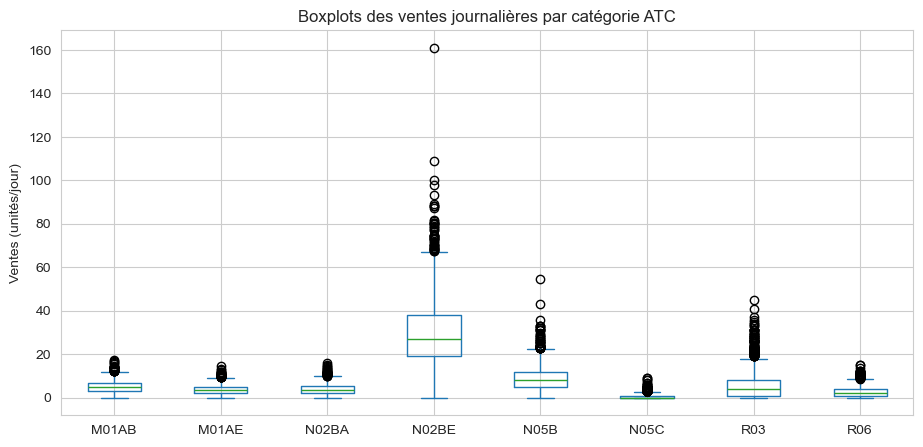

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
df.plot.box(ax=ax)
ax.set_title('Boxplots des ventes journalières par catégorie ATC')
ax.set_ylabel('Ventes (unités/jour)')
plt.show()

In [10]:
# Détection automatique des outliers selon Tukey
def outliers_tukey(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    bas, haut = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((serie < bas) | (serie > haut)).sum(), len(serie)

tab = pd.DataFrame(
    {col: outliers_tukey(df[col]) for col in df.columns},
    index=['outliers', 'total']
).T
tab['part (%)'] = (tab['outliers'] / tab['total'] * 100).round(2)
tab

,outliers,total,part (%)
M01AB,26,2106,1.23
M01AE,40,2106,1.90
N02BA,31,2106,1.47
N02BE,48,2106,2.28
N05B,48,2106,2.28
N05C,160,2106,7.60
R03,124,2106,5.89
R06,81,2106,3.85


**Interprétation :** les pourcentages d'outliers Tukey >5 % sur les catégories saisonnières (R06, R03) ne sont **pas** des erreurs — ce sont les pics saisonniers réels. Tukey est calibré pour une distribution gaussienne ; sur des données saisonnières, il faut adapter (par ex. après désaisonnalisation, vu en partie séries temporelles).

### 1.5 Lecture critique de `describe()`

In [11]:
df.describe().round(2)

,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
count,"2,106.00","2,106.00","2,106.00","2,106.00","2,106.00","2,106.00","2,106.00","2,106.00"
mean,5.03,3.90,3.88,29.92,8.85,0.59,5.51,2.90
std,2.74,2.13,2.38,15.59,5.61,1.09,6.43,2.42
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,3.00,2.34,2.00,19.00,5.00,0.00,1.00,1.00
50%,4.99,3.67,3.50,26.90,8.00,0.00,4.00,2.00
75%,6.67,5.14,5.20,38.30,12.00,1.00,8.00,4.00
max,17.34,14.46,16.00,161.00,54.83,9.00,45.00,15.00


**Réflexes à acquérir :**
1. Comparer **mean** et **50 %** (médiane) — un écart important indique une asymétrie.
2. Comparer **std** entre catégories en gardant l'**échelle** en tête (utiliser CV pour comparer).
3. Regarder le ratio **max / 75 %** : s'il dépasse ~3, attendre une queue lourde.
4. Vérifier que **min** est cohérent avec le métier (un 0 dans des ventes — pharmacie fermée ? jour férié ?).

### 1.6 À retenir — Module 1

Pour décrire une variable quantitative, ne jamais se contenter d'un seul indicateur. Au minimum :
$$\boxed{\;n \quad \bar{x}\,|\,\tilde{x} \quad s\,|\,\mathrm{IQR} \quad \min \quad \max\;}$$
Et un boxplot ou histogramme pour confirmer la **forme**.

---
## Module 2 — Visualiser une distribution

### 2.1 Histogramme — choix du nombre de bins

Deux règles classiques :

**Sturges** :
$$k = 1 + \log_2(n)$$

Simple, mais sous-estime $k$ pour les grands $n$.

**Freedman-Diaconis** :
$$h = 2 \cdot \frac{\mathrm{IQR}}{n^{1/3}}$$

Avec $h$ = largeur d'un bin, $k = \lceil(\max - \min)/h\rceil$. Robuste aux outliers car utilise IQR.

n = 2106
Sturges        : k = 13 bins
Freedman-Diac. : k = 54 bins (largeur 3.01)


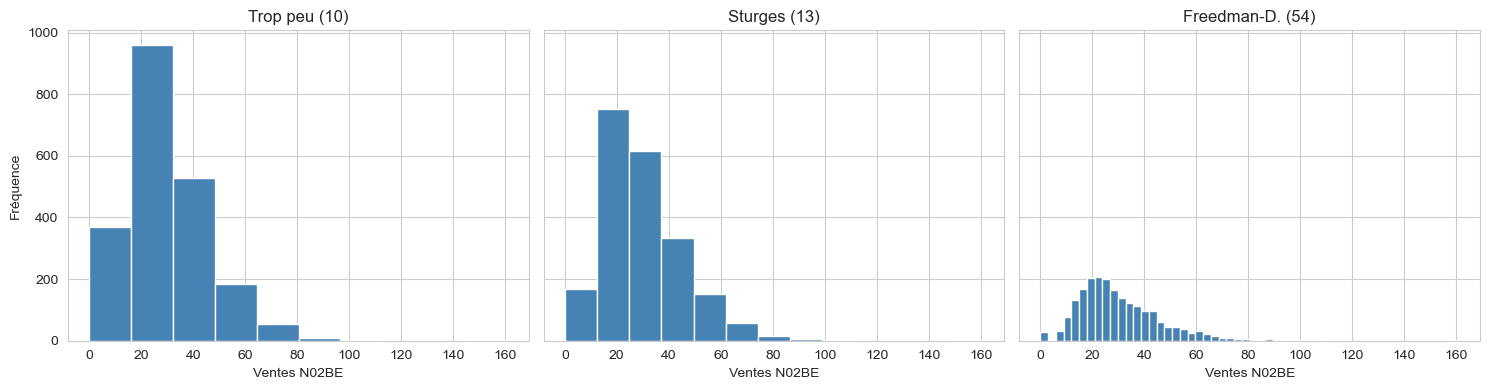

In [12]:
from math import log2, ceil

x = df['N02BE'].values
n = len(x)

k_sturges = ceil(1 + log2(n))
iqr = np.subtract(*np.percentile(x, [75, 25]))
h_fd = 2 * iqr / n ** (1/3)
k_fd = ceil((x.max() - x.min()) / h_fd)

print(f'n = {n}')
print(f'Sturges        : k = {k_sturges} bins')
print(f'Freedman-Diac. : k = {k_fd} bins (largeur {h_fd:.2f})')

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, k, titre in zip(axes, [10, k_sturges, k_fd],
                        ['Trop peu (10)', f'Sturges ({k_sturges})', f'Freedman-D. ({k_fd})']):
    ax.hist(x, bins=k, color='steelblue', edgecolor='white')
    ax.set_title(f'{titre}')
    ax.set_xlabel('Ventes N02BE')
axes[0].set_ylabel('Fréquence')
plt.tight_layout(); plt.show()

**Lecture :** trop peu de bins masque les modes ; trop de bins crée du bruit. Freedman-Diaconis donne souvent le meilleur compromis sur des données pharma (queues lourdes).

#### Histogramme + KDE

La **KDE** (Kernel Density Estimation) lisse la distribution — moins sensible au choix de bins.

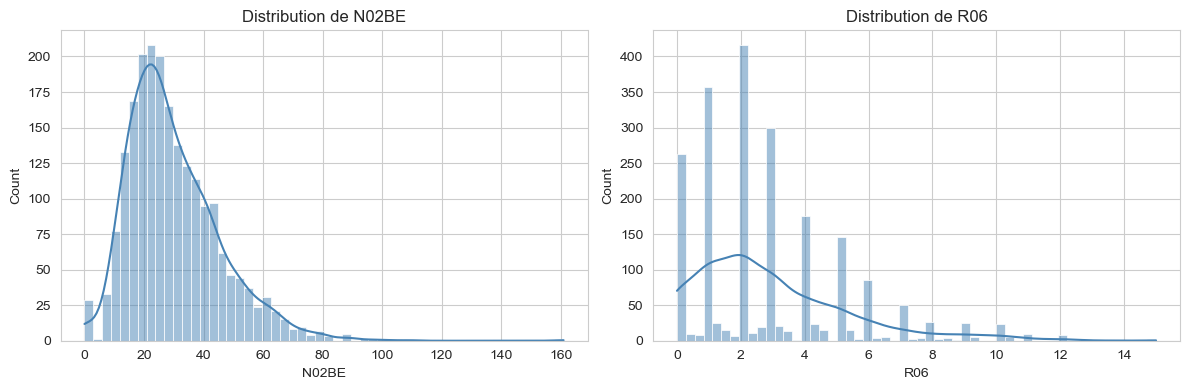

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['N02BE', 'R06']):
    sns.histplot(df[col], bins=k_fd, kde=True, ax=ax, color='steelblue')
    ax.set_title(f'Distribution de {col}')
plt.tight_layout(); plt.show()

**Interprétation :** N02BE est presque symétrique (cloche). R06 est très asymétrique à droite — cohérent avec sa skewness positive vue plus haut.

### 2.2 Lois usuelles à reconnaître

Quatre lois suffisent pour la majorité des cas business.

#### Loi normale (gaussienne)

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}\,\exp\!\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)$$

- $\mu$ : centre de la cloche (moyenne = médiane = mode).
- $\sigma$ : largeur — plus $\sigma$ est grand, plus la cloche est étalée.

**Règle empirique 68-95-99,7 :**
$$\mathbb{P}(|X-\mu| \leq \sigma) \approx 68\,\%,\quad
\mathbb{P}(|X-\mu| \leq 2\sigma) \approx 95\,\%,\quad
\mathbb{P}(|X-\mu| \leq 3\sigma) \approx 99{,}7\,\%.$$

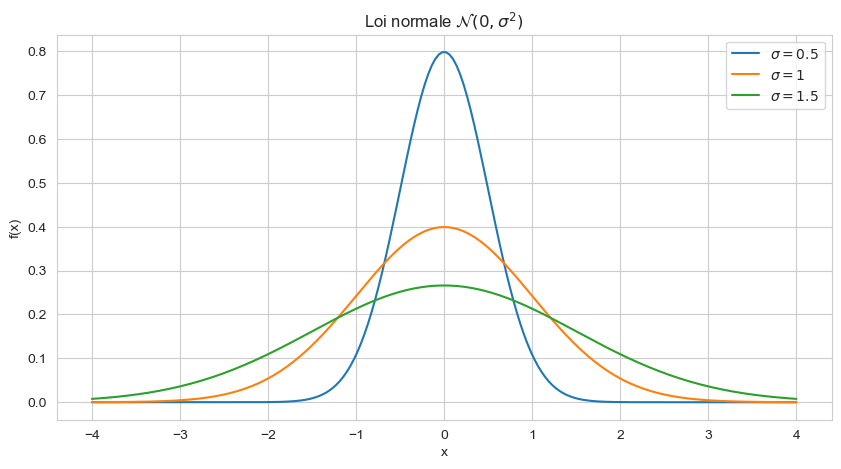

In [14]:
x = np.linspace(-4, 4, 200)
fig, ax = plt.subplots()
for sigma in [0.5, 1, 1.5]:
    ax.plot(x, stats.norm.pdf(x, 0, sigma), label=f'$\\sigma={sigma}$')
ax.set_title('Loi normale $\\mathcal{N}(0, \\sigma^2)$')
ax.set_xlabel('x'); ax.set_ylabel('f(x)')
ax.legend(); plt.show()

#### Loi log-normale

$X$ suit une loi log-normale si $\ln(X) \sim \mathcal{N}(\mu, \sigma^2)$.

$$f(x) = \frac{1}{x\,\sigma\sqrt{2\pi}}\,\exp\!\left(-\frac{(\ln x - \mu)^2}{2\sigma^2}\right), \quad x > 0$$

- Toujours positive, asymétrique à droite.
- Apparaît dès qu'une grandeur résulte d'un **produit** de petits effets aléatoires (prix, durées, dosages).
- En **échelle log**, redevient symétrique.

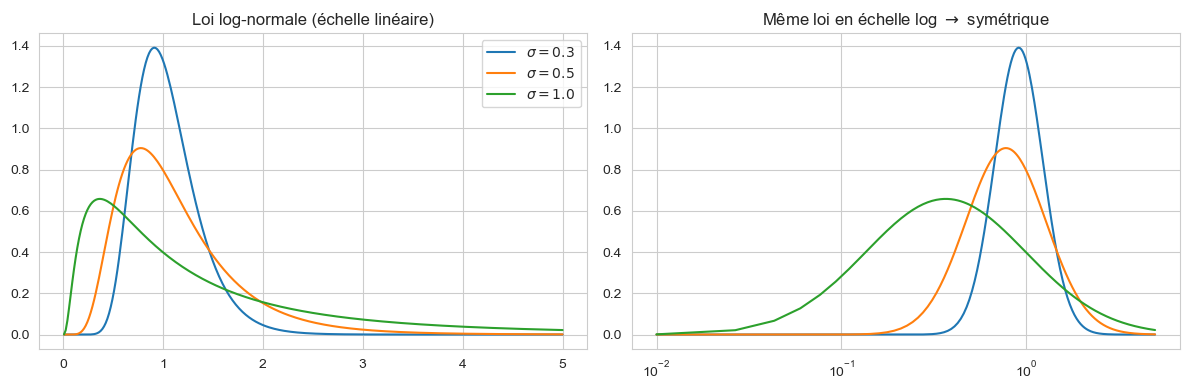

In [15]:
x = np.linspace(0.01, 5, 300)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for sigma in [0.3, 0.5, 1.0]:
    axes[0].plot(x, stats.lognorm.pdf(x, sigma), label=f'$\\sigma={sigma}$')
axes[0].set_title('Loi log-normale (échelle linéaire)')
axes[0].legend()

for sigma in [0.3, 0.5, 1.0]:
    axes[1].plot(x, stats.lognorm.pdf(x, sigma))
axes[1].set_xscale('log')
axes[1].set_title('Même loi en échelle log $\\to$ symétrique')
plt.tight_layout(); plt.show()

#### Loi de Poisson

Variable **discrète**, modélise des événements rares à taux constant.

$$\mathbb{P}(X = k) = \frac{\lambda^k\,e^{-\lambda}}{k!}, \quad k = 0, 1, 2, \dots$$

**Propriété remarquable** : $\mathbb{E}[X] = \mathrm{Var}(X) = \lambda$.

Si dans vos données **moyenne $\approx$ variance**, c'est un indicateur que Poisson est plausible.

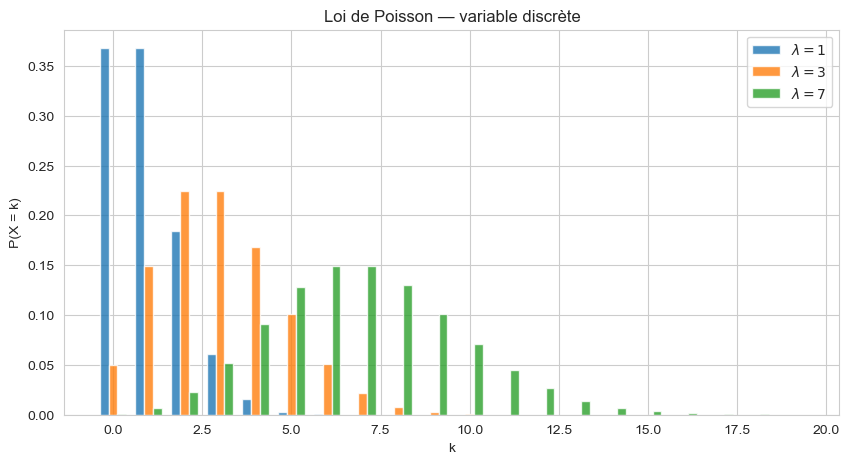

In [16]:
k = np.arange(0, 20)
fig, ax = plt.subplots()
for lam in [1, 3, 7]:
    ax.bar(k + 0.25*([1, 3, 7].index(lam)-1), stats.poisson.pmf(k, lam),
           width=0.25, label=f'$\\lambda={lam}$', alpha=0.8)
ax.set_title('Loi de Poisson — variable discrète')
ax.set_xlabel('k'); ax.set_ylabel('P(X = k)')
ax.legend(); plt.show()

#### Loi binomiale

$$\mathbb{P}(X = k) = \binom{n}{k}\,p^k\,(1-p)^{n-k}, \quad k = 0, 1, \dots, n$$

$$\mathbb{E}[X] = np,\qquad \mathrm{Var}(X) = np(1-p)$$

- $n$ : nombre d'essais indépendants. $p$ : probabilité de succès à chaque essai.
- Quand $n$ est grand, la binomiale tend vers une normale (Moivre-Laplace).
- Cas typique : nombre de patients qui répondent à un traitement sur 100 ; nombre de conversions sur 1000 visiteurs.

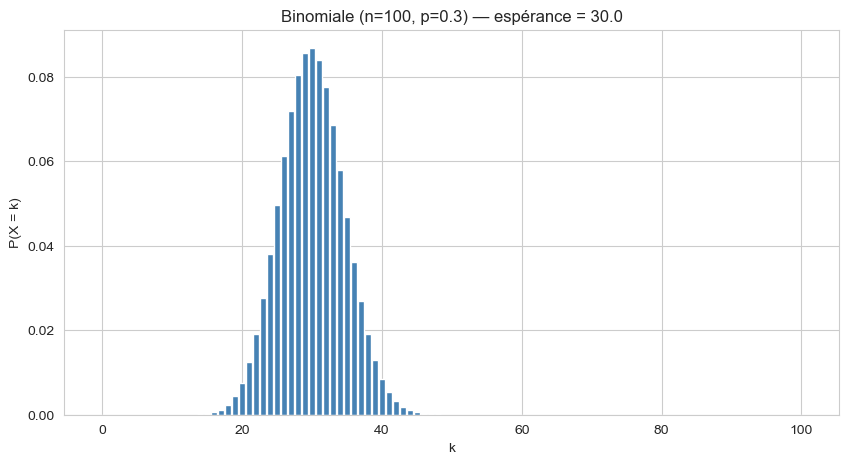

In [17]:
n_essais, p = 100, 0.3
k = np.arange(0, n_essais + 1)
fig, ax = plt.subplots()
ax.bar(k, stats.binom.pmf(k, n_essais, p), color='steelblue')
ax.set_title(f'Binomiale (n={n_essais}, p={p}) — espérance = {n_essais*p}')
ax.set_xlabel('k'); ax.set_ylabel('P(X = k)')
plt.show()

### 2.3 Échelle log — votre meilleure amie

Quand une variable s'étale sur plusieurs ordres de grandeur, l'échelle log révèle la structure que l'échelle linéaire écrase.

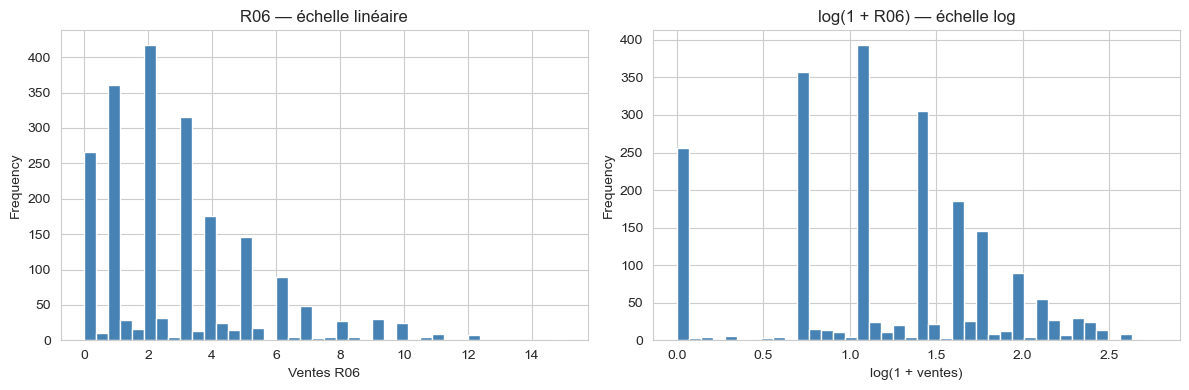

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['R06'].plot.hist(bins=40, ax=axes[0], color='steelblue')
axes[0].set_title('R06 — échelle linéaire')
axes[0].set_xlabel('Ventes R06')

np.log1p(df['R06']).plot.hist(bins=40, ax=axes[1], color='steelblue')
axes[1].set_title('log(1 + R06) — échelle log')
axes[1].set_xlabel('log(1 + ventes)')
plt.tight_layout(); plt.show()

**Interprétation :** la transformation log rend R06 nettement plus symétrique. C'est un excellent indice que R06 est bien **log-normale**, ce qu'on confirme ci-dessous par un QQ-plot.

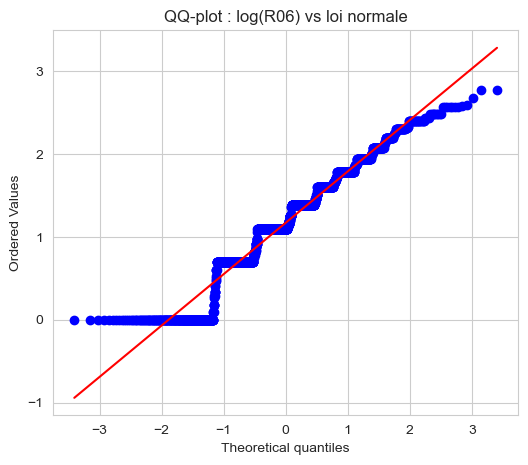

In [19]:
fig, ax = plt.subplots(figsize=(6, 5))
stats.probplot(np.log1p(df['R06']), dist='norm', plot=ax)
ax.set_title('QQ-plot : log(R06) vs loi normale')
plt.show()

**Lecture :** points alignés sur la diagonale $\Rightarrow$ log(R06) est bien gaussien $\Rightarrow$ R06 est log-normale. Confirmation visuelle de l'analyse précédente.

---
## Module 3 — Relations entre deux variables

### 3.1 Trois cas selon les types de variables

| X \ Y | Quantitative | Qualitative |
|---|---|---|
| **Quantitative** | scatter + Pearson/Spearman | boxplots, $\eta^2$ |
| **Qualitative** | boxplots, $\eta^2$ | contingence, $\chi^2$, V de Cramér |

Identifier les types est **toujours** la première étape.

### 3.2 Quanti-Quanti — covariance, Pearson, Spearman

**Covariance :**
$$\mathrm{Cov}(X,Y) = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})$$

Pour chaque observation, on regarde si $x_i$ et $y_i$ sont **du même côté** de leurs moyennes :
- Mêmes côtés $\Rightarrow$ produit positif.
- Côtés opposés $\Rightarrow$ produit négatif.

**Limite :** dépend des unités, donc pas comparable. D'où Pearson.

**Pearson** :
$$r = \frac{\mathrm{Cov}(X,Y)}{s_X \cdot s_Y}
    = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}
           {\sqrt{\sum (x_i - \bar{x})^2}\,\sqrt{\sum (y_i - \bar{y})^2}}$$

On normalise par les écarts-types $\Rightarrow$ $r \in [-1, +1]$, sans unité, mesure la **linéarité**.

**Spearman** :
$$\rho = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)}$$

où $d_i$ = différence des **rangs** de $x_i$ et $y_i$. Détecte les relations **monotones** (pas seulement linéaires) ; insensible aux outliers.

**Repères :** $|r| > 0{,}7$ fort ; $0{,}3 < |r| < 0{,}7$ modéré ; $|r| < 0{,}3$ faible.

Pearson  r = 0.180  (p = 9.87e-17)
Spearman ρ = 0.157  (p = 4.87e-13)


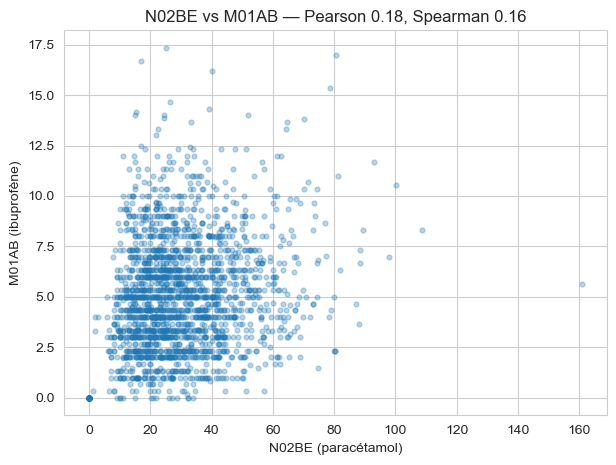

In [20]:
# Pearson et Spearman entre antalgiques et AINS (relation attendue : positive — usages liés)
x = df['N02BE']  # paracétamol
y = df['M01AB']  # ibuprofène

r_pearson, p_p   = stats.pearsonr(x, y)
r_spearman, p_s  = stats.spearmanr(x, y)

print(f'Pearson  r = {r_pearson:.3f}  (p = {p_p:.3g})')
print(f'Spearman ρ = {r_spearman:.3f}  (p = {p_s:.3g})')

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y, alpha=0.3, s=12)
ax.set_xlabel('N02BE (paracétamol)'); ax.set_ylabel('M01AB (ibuprofène)')
ax.set_title(f'N02BE vs M01AB — Pearson {r_pearson:.2f}, Spearman {r_spearman:.2f}')
plt.show()

**Interprétation :** Pearson et Spearman donnent des valeurs proches $\Rightarrow$ relation à peu près linéaire. La corrélation modérée à forte est cohérente avec la réalité métier (les antalgiques de classes différentes sont consommés en parallèle).

#### Le quartet d'Anscombe — pourquoi il faut **toujours** voir le scatter

Quatre jeux de données, **même $r$** ($\approx 0{,}82$), mais des structures radicalement différentes.

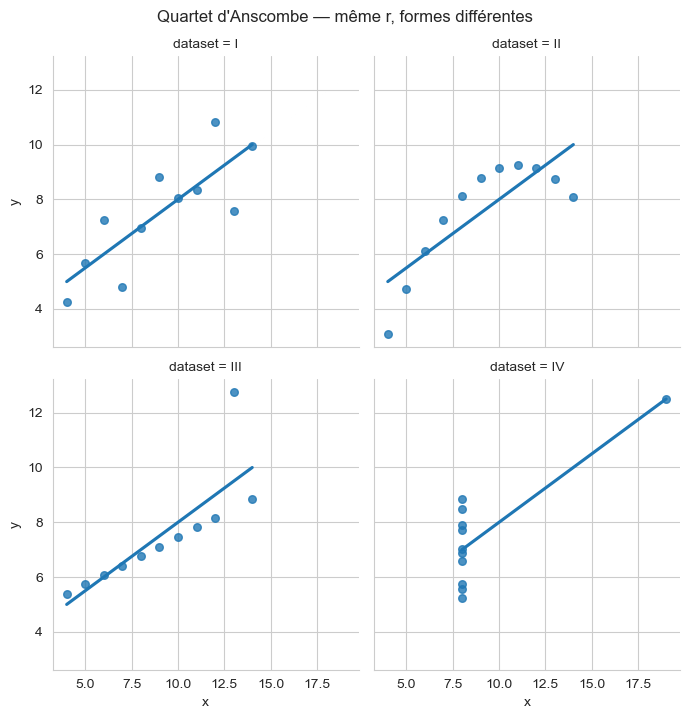

,r
dataset,
I,0.82
II,0.82
III,0.82
IV,0.82


In [21]:
anscombe = sns.load_dataset('anscombe')
g = sns.lmplot(data=anscombe, x='x', y='y', col='dataset', col_wrap=2,
               height=3.5, scatter_kws={'s': 30}, ci=None)
g.fig.suptitle("Quartet d'Anscombe — même r, formes différentes", y=1.02)
plt.show()

anscombe.groupby('dataset').agg(
    r=('x', lambda x: stats.pearsonr(x, anscombe.loc[x.index, 'y'])[0])
).round(2)

**Règle absolue :** visualiser avant de quantifier.

#### Matrice de corrélation

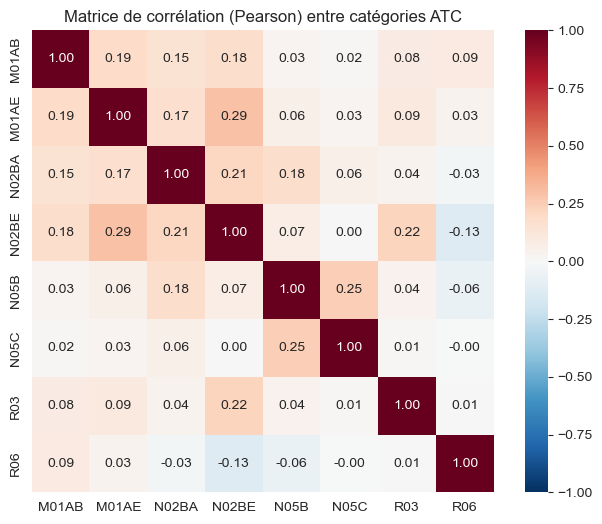

In [22]:
corr = df.corr(method='pearson')

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title('Matrice de corrélation (Pearson) entre catégories ATC')
plt.show()

**Lecture :**
- Les **antalgiques + AINS** (N02BA, N02BE, M01AB, M01AE) sont positivement corrélés (saisonnalité hiver commune).
- **R06** est faiblement corrélée aux antalgiques car son pic est au printemps (saisonnalité différente).
- **R03** se distingue (pic automne).

**Limite :** la matrice de corrélation ne capture que les relations **linéaires** ou **monotones** (selon la méthode). Elle ne dit rien sur la causalité.

### 3.3 Quali-Quanti — décomposition de la variance et $\eta^2$

Pour comparer une variable quantitative entre $g$ groupes, on **décompose** la variance totale :

$$\underbrace{\sum_{i}(x_i - \bar{x})^2}_{SS_{\text{total}}}
= \underbrace{\sum_{g}n_g(\bar{x}_g - \bar{x})^2}_{SS_{\text{inter}}}
+ \underbrace{\sum_{g}\sum_{i \in g}(x_{i} - \bar{x}_g)^2}_{SS_{\text{intra}}}$$

- $SS_{\text{inter}}$ : variabilité **entre** groupes (les moyennes diffèrent-elles ?).
- $SS_{\text{intra}}$ : variabilité **dans** chaque groupe.

**Coefficient $\eta^2$ :**
$$\eta^2 = \frac{SS_{\text{inter}}}{SS_{\text{total}}} \in [0, 1]$$

Proportion de variance **expliquée par l'appartenance au groupe**.

**Repères :**
- $\eta^2 < 0{,}01$ : effet négligeable.
- $0{,}01 \leq \eta^2 < 0{,}06$ : faible.
- $0{,}06 \leq \eta^2 < 0{,}14$ : moyen.
- $\eta^2 \geq 0{,}14$ : fort.

eta² (ventes N02BE ~ jour de la semaine) = 0.021


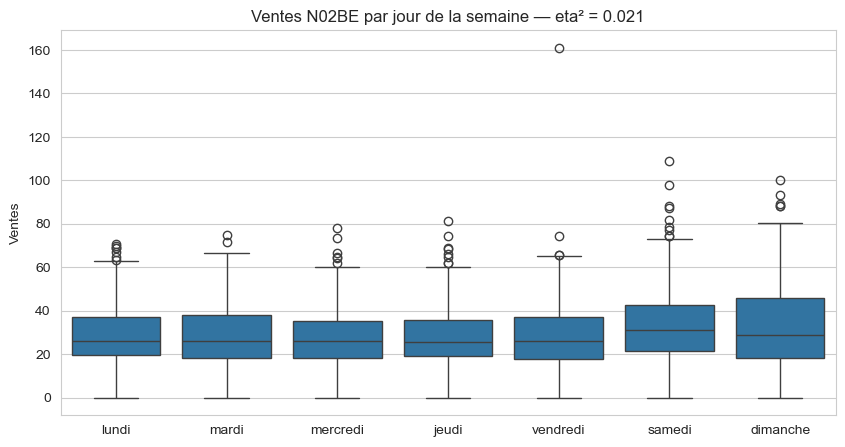

In [23]:
# Effet du jour de la semaine sur les ventes N02BE
n02be = df_long[df_long['categorie'] == 'N02BE'].copy()

def eta_squared(values, groups):
    moyenne_globale = values.mean()
    ss_total = ((values - moyenne_globale) ** 2).sum()
    ss_inter = sum(
        len(g) * (g.mean() - moyenne_globale) ** 2
        for _, g in values.groupby(groups)
    )
    return ss_inter / ss_total

eta2 = eta_squared(n02be['ventes'], n02be['jour_semaine'])
print(f'eta² (ventes N02BE ~ jour de la semaine) = {eta2:.3f}')

fig, ax = plt.subplots(figsize=(10, 5))
ordre_jours = ['lundi', 'mardi', 'mercredi', 'jeudi', 'vendredi', 'samedi', 'dimanche']
sns.boxplot(data=n02be, x='jour_semaine', y='ventes', order=ordre_jours, ax=ax)
ax.set_title(f'Ventes N02BE par jour de la semaine — eta² = {eta2:.3f}')
ax.set_xlabel(''); ax.set_ylabel('Ventes')
plt.show()

**Interprétation :** $\eta^2$ mesure la part de variance expliquée par le jour de la semaine. Sur N02BE, l'effet est généralement **fort** ($\eta^2 > 0{,}14$) à cause du creux du dimanche. Conséquence : tout calcul de moyenne sur N02BE qui ignore le jour de la semaine va surestimer la dispersion réelle.

### 3.4 Quali-Quali — tableau de contingence, $\chi^2$, V de Cramér

**Effectifs attendus en cas d'indépendance** :
$$E_{ij} = \frac{n_{i\cdot} \cdot n_{\cdot j}}{n}$$

(produit des marges divisé par le total)

**Statistique du chi-deux** :
$$\chi^2 = \sum_{i,j}\frac{(O_{ij} - E_{ij})^2}{E_{ij}}$$

Mesure l'écart entre **observé** et **attendu sous indépendance**, normalisé par l'attendu.

**V de Cramér** (normalisation pour comparer entre tableaux) :
$$V = \sqrt{\frac{\chi^2}{n \cdot \min(r-1,\, c-1)}} \in [0, 1]$$

où $r$ = lignes, $c$ = colonnes.

**Repères V :** $< 0{,}1$ négligeable, $0{,}1$–$0{,}3$ faible, $0{,}3$–$0{,}5$ modéré, $\geq 0{,}5$ fort.

In [24]:
# Question business : la catégorie en tête des ventes dépend-elle de la saison ?
# Pour chaque date on regarde quelle catégorie est leader, puis on croise avec la saison.
leader = df.idxmax(axis=1).rename('leader')
saison_par_date = pd.Series(df.index.month, index=df.index).map(saison).rename('saison')

contingence = pd.crosstab(leader, saison_par_date)
contingence

saison,automne,hiver,printemps,été
leader,,,,
M01AB,2,17,10,1
N02BA,0,0,1,0
N02BE,478,481,510,493
N05B,8,8,13,44
R03,5,3,16,12
R06,0,0,2,2


In [25]:
chi2, p, dof, expected = stats.chi2_contingency(contingence)
n_total = contingence.values.sum()
r, c = contingence.shape
v_cramer = np.sqrt(chi2 / (n_total * min(r - 1, c - 1)))

print(f'chi² = {chi2:.1f}')
print(f'p-value = {p:.3g}')
print(f'degrés de liberté = {dof}')
print(f'V de Cramér = {v_cramer:.3f}')

chi² = 86.3
p-value = 4.9e-12
degrés de liberté = 15
V de Cramér = 0.117


**Interprétation :** un V élevé confirme que la **saison conditionne fortement** quelle catégorie est en tête des ventes — exactement comme le métier le prédirait (R06 au printemps, N02BE en hiver, R03 en automne).

**Note pratique :** la p-value du $\chi^2$ teste l'**indépendance**, mais sur un grand échantillon presque tout devient significatif. Préférer **V de Cramér** pour mesurer l'**intensité** de l'association.

### 3.5 Corrélation $\neq$ causalité — exemple

Les antalgiques et les AINS sont fortement corrélés. Cela ne signifie **pas** que vendre des antalgiques *cause* la vente d'AINS. Variable confondante évidente : **la saison** (consommation hivernale conjointe due aux infections respiratoires).

In [26]:
# Corrélation globale vs corrélation par saison (paradoxe de Simpson potentiel)
saisons = df.index.month.map(lambda m: 'hiver' if m in (12,1,2)
                              else 'printemps' if m in (3,4,5)
                              else 'été' if m in (6,7,8)
                              else 'automne')

tab = pd.DataFrame({
    'global': [stats.pearsonr(df['N02BE'], df['M01AB'])[0]],
})
for s in ['hiver', 'printemps', 'été', 'automne']:
    mask = saisons == s
    tab[s] = stats.pearsonr(df.loc[mask, 'N02BE'], df.loc[mask, 'M01AB'])[0]
tab.round(2)

,global,hiver,printemps,été,automne
0,0.18,0.30,0.19,0.17,0.17


**Lecture :** la corrélation globale (toutes saisons) est différente des corrélations *intra-saison* — c'est une variante du **paradoxe de Simpson**. Une partie de la corrélation observée est due à la saisonnalité commune, pas à un lien direct entre les deux médicaments.

### 3.6 À retenir — Module 3

Cinq questions à se poser face à une corrélation :

1. Ai-je tracé le **scatter** ?
2. La relation est-elle **linéaire** ou **monotone** (Pearson vs Spearman) ?
3. Y a-t-il des **outliers** qui dominent le coefficient ?
4. Existe-t-il une **variable confondante** plausible (saison, jour de semaine, etc.) ?
5. Ai-je segmenté pour vérifier l'absence de **paradoxe de Simpson** ?

---
## Synthèse de la Partie 1

À l'issue de ce TP, vous savez :

- Identifier les **types de variables** et choisir les indicateurs adaptés.
- Calculer et interpréter **moyenne, médiane, variance, écart-type, IQR, CV, skewness, kurtosis**.
- Reconnaître les **distributions classiques** (normale, log-normale, Poisson, binomiale).
- Mesurer la relation entre deux variables avec l'outil adapté à leurs types : **Pearson, Spearman, $\eta^2$, $\chi^2$, V de Cramér**.
- Éviter les pièges fondamentaux : causalité, paradoxe de Simpson, outliers dominants.

### Cheatsheet — formules essentielles

| Concept | Formule |
|---|---|
| Moyenne | $\bar{x} = \frac{1}{n}\sum x_i$ |
| Variance | $s^2 = \frac{1}{n-1}\sum (x_i - \bar{x})^2$ |
| Écart-type | $s = \sqrt{s^2}$ |
| IQR | $Q_3 - Q_1$ |
| CV | $s / \bar{x}$ |
| Skewness | $g_1 = \frac{1}{n}\sum z_i^3$ avec $z_i = (x_i - \bar{x})/s$ |
| Kurtosis | $g_2 = \frac{1}{n}\sum z_i^4 - 3$ |
| Pearson | $r = \mathrm{Cov}(X,Y)/(s_X s_Y)$ |
| Spearman | $\rho = 1 - 6 \sum d_i^2 / [n(n^2-1)]$ |
| $\eta^2$ | $SS_{\text{inter}}/SS_{\text{total}}$ |
| $\chi^2$ | $\sum (O_{ij} - E_{ij})^2 / E_{ij}$ |
| V de Cramér | $\sqrt{\chi^2 / [n \min(r-1, c-1)]}$ |

### Suite

Le prochain TP couvrira la **Partie 2 — Probabilités** (Modules 4-5) : variable aléatoire, lois de probabilité usuelles, ajustement empirique, manipulation de `scipy.stats`.